# Klasyfikacja cyfr MNIST: MLP i CNN - Mateusz Nowak, Filip Czech

**Cel:** zbudować i porównać MLP oraz CNN, dobrać hiperparametry i sprawdzić, czy głębsza CNN oraz inicjalizacja HeUniform rzeczywiście pomagają.



In [7]:
# Uruchom raz, jeśli brakuje bibliotek, a następnie zrestartuj kernel.
%pip install "tensorflow>=2.16,<2.22" "optuna>=4,<6" numpy pandas matplotlib scikit-learn nbformat nbclient ipykernel

In [8]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
from pathlib import Path
import json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import optuna
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

PROFILE = os.environ.get("MNIST_PROFILE", "full")  # full lub smoke
assert PROFILE in {"full", "smoke"}
SMOKE = PROFILE == "smoke"
SEED = 42
CFG = dict(epochs=2 if SMOKE else 20, trials_mlp=2 if SMOKE else 12,
           trials_cnn=2 if SMOKE else 20, seeds=[42] if SMOKE else [42, 123, 2026])
OUT = Path("wyniki_mnist") / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("Profil:", PROFILE, "| Python:", platform.python_version(), "| TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"), "| Budżet:", CFG)
if SMOKE:
    print("UWAGA: mała próbka i krótki trening — tylko kontrola działania kodu.")

Profil: full | Python: 3.13.15 | TF: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | Budżet: {'epochs': 20, 'trials_mlp': 12, 'trials_cnn': 20, 'seeds': [42, 123, 2026]}


## 1-3. Dane, przykładowe obrazy i przygotowanie
MNIST z Keras zawiera 60 000 obrazów treningowych i 10 000 testowych. Z pierwszej części wydzielamy **10 000 obrazów walidacyjnych** ze stratyfikacją, zachowując proporcje cyfr. Trening wykorzystuje zatem 50 000 obrazów. Ten sam podział obowiązuje wszystkie modele.

Piksele dzielimy przez 255 (bez dopasowywania statystyk do testu). Etykieta `3` staje się wektorem `[0,0,0,1,0,0,0,0,0,0]`. Dzięki one-hot używamy `categorical_crossentropy`. CNN otrzymuje tensor `(N,28,28,1)`, a MLP spłaszcza obraz wewnątrz modelu. Dane testowe pozostają odłożone do końcowej oceny.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


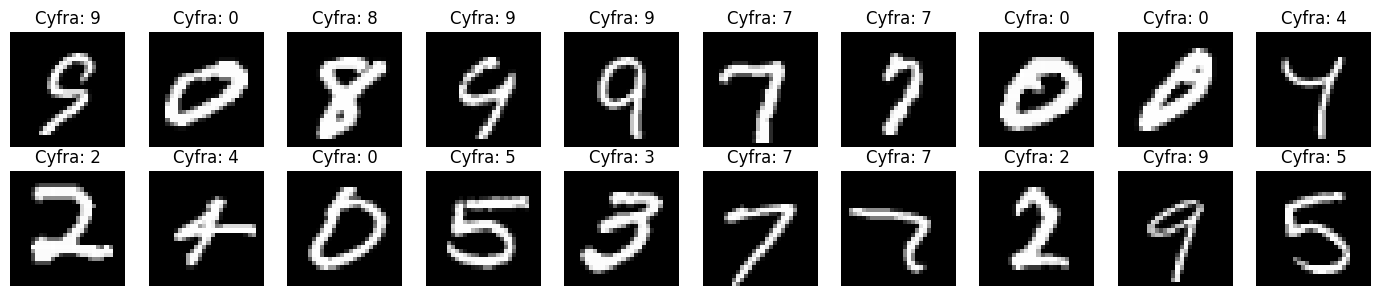

Train / val / test: (50000, 28, 28, 1) (10000, 28, 28, 1) (10000, 28, 28, 1)
Przykład one-hot: 7 → [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


,trening,walidacja
0,4936,987
1,5618,1124
2,4965,993
3,5109,1022
4,4868,974
5,4518,903
6,4932,986
7,5221,1044
8,4876,975
9,4957,992


In [9]:
(x_raw, y_raw), (x_test_raw, y_test_int) = keras.datasets.mnist.load_data()
assert x_raw.shape == (60000, 28, 28) and x_test_raw.shape == (10000, 28, 28)
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for ax, i in zip(axes.flat, np.random.default_rng(SEED).choice(len(x_raw), 20, replace=False)):
    ax.imshow(x_raw[i], cmap="gray"); ax.set_title(f"Cyfra: {y_raw[i]}"); ax.axis("off")
plt.tight_layout(); plt.show()
train_idx, val_idx = train_test_split(np.arange(len(y_raw)), test_size=10000,
                                     stratify=y_raw, random_state=SEED)
if SMOKE:
    train_idx, _ = train_test_split(train_idx, train_size=2000, stratify=y_raw[train_idx], random_state=SEED)
    val_idx, _ = train_test_split(val_idx, train_size=1000, stratify=y_raw[val_idx], random_state=SEED)
x_train = (x_raw[train_idx].astype("float32") / 255)[..., None]
x_val = (x_raw[val_idx].astype("float32") / 255)[..., None]
x_test = (x_test_raw.astype("float32") / 255)[..., None]
y_train = keras.utils.to_categorical(y_raw[train_idx], 10)
y_val = keras.utils.to_categorical(y_raw[val_idx], 10)
y_test = keras.utils.to_categorical(y_test_int, 10)
assert x_train.min() >= 0 and x_train.max() <= 1
assert np.allclose(y_train.sum(axis=1), 1)
print("Train / val / test:", x_train.shape, x_val.shape, x_test.shape)
print("Przykład one-hot:", y_raw[train_idx[0]], "→", y_train[0])
display(pd.DataFrame({"trening": np.bincount(y_raw[train_idx], minlength=10),
                      "walidacja": np.bincount(y_raw[val_idx], minlength=10)}, index=range(10)))

## Wspólny sposób treningu i oceny
Wszystkie modele optymalizuje Adam. Wybieramy wagi o najmniejszej **walidacyjnej entropii krzyżowej** (`val_loss`), ponieważ uwzględnia ona również pewność przewidywań. Accuracy i macro-F1 będą dodatkowymi miarami.

`EarlyStopping` przywraca najlepsze wagi, a `ReduceLROnPlateau` zmniejsza krok uczenia po stagnacji. Każdy trening otrzymuje nowe callbacki. Budżet epok jest wspólny, ale czas i liczba parametrów mogą się różnić — raportujemy je. Test nie jest przekazywany do funkcji treningu ani Optuny.

In [10]:
records, histories, model_paths = [], {}, {}
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

def train_model(builder, params, seed=SEED):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model = builder(**params)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]
    start = time.perf_counter()
    h = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                  batch_size=params.get("batch_size", 128), epochs=CFG["epochs"],
                  callbacks=callbacks, verbose=0).history
    seconds = time.perf_counter() - start
    metrics = model.evaluate(x_val, y_val, verbose=0, return_dict=True)
    return model, h, dict(val_loss=metrics["loss"], val_accuracy=metrics["accuracy"],
                         seconds=seconds, parameters=model.count_params(),
                         epochs=len(h["loss"]), best_epoch=int(np.argmin(h["val_loss"])) + 1)

def run_named(name, builder, params, seed=SEED):
    model, h, row = train_model(builder, params, seed)
    path = OUT / f"{name}.keras"
    model.save(path)
    model_paths[name] = path
    histories[name] = h
    records.append(dict(name=name, seed=seed, **row))
    print(name, {k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
    return model

def plot_history(name):
    h = histories[name]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(range(1, len(h[metric])+1), h[metric], label="trening")
        ax.plot(range(1, len(h[metric])+1), h["val_"+metric], label="walidacja")
        ax.set(xlabel="Epoka", ylabel=metric, title=name); ax.legend(); ax.grid(alpha=.2)
    plt.tight_layout(); plt.show()
    i = int(np.argmin(h["val_loss"]))
    gap = h["accuracy"][i] - h["val_accuracy"][i]
    display(Markdown(f"Najmniejsza strata walidacyjna wystąpiła w epoce **{i+1}**. "
                     f"Różnica train–validation accuracy w tej epoce: **{100*gap:.2f} p.p.** "
                     "Rosnąca strata walidacyjna przy malejącej treningowej sugeruje przeuczenie. "
                     "Przy Dropout i augmentacji metryki treningowe dotyczą trudniejszych warunków niż walidacyjne."))

## 4–6. MLP: punkt odniesienia i optymalizacja
MLP otrzymuje 784 liczby. Warstwa Dense łączy każdy piksel z każdym neuronem następnej warstwy. Bazowy model ma 128 neuronów i ReLU. Stroimy liczbę warstw, szerokość, Dropout, learning rate i rozmiar batcha. Liczbę epok ogranicza wspólny budżet i early stopping.

Najpierw oceniamy walidację. Predykcje testowe i końcowa dokładność pojawią się we wspólnej sekcji testowej, aby kolejne decyzje nie zależały od testu.

MLP_base {'val_loss': 0.0858, 'val_accuracy': 0.9791, 'seconds': 58.3228, 'parameters': 101770, 'epochs': 20, 'best_epoch': 17}


Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

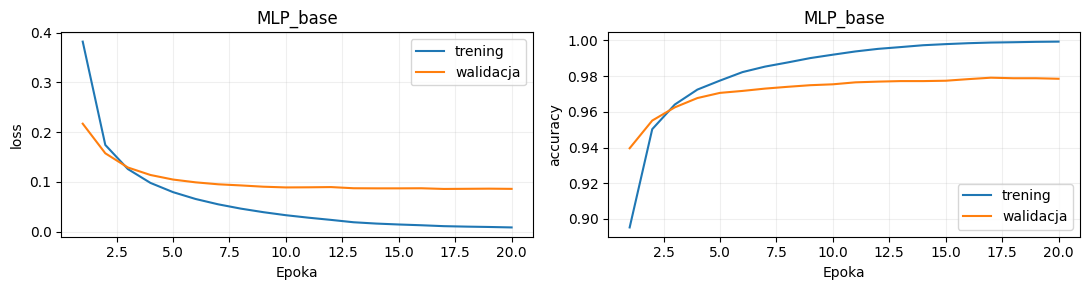

Najmniejsza strata walidacyjna wystąpiła w epoce **17**. Różnica train–validation accuracy w tej epoce: **1.97 p.p.** Rosnąca strata walidacyjna przy malejącej treningowej sugeruje przeuczenie. Przy Dropout i augmentacji metryki treningowe dotyczą trudniejszych warunków niż walidacyjne.

In [11]:
def build_mlp(width=128, depth=1, dropout=0.0, lr=1e-3, batch_size=128):
    model = keras.Sequential([keras.Input((28, 28, 1)), layers.Flatten()], name="MLP")
    for _ in range(depth):
        model.add(layers.Dense(width, activation="relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))
    return compile_model(model, lr)

mlp_base = run_named("MLP_base", build_mlp, {})
mlp_base.summary()
plot_history("MLP_base")

Najlepsze parametry MLP: {'width': 256, 'depth': 1, 'dropout': 0.4, 'lr': 0.0005958389350068958, 'batch_size': 64}
MLP_tuned {'val_loss': 0.0673, 'val_accuracy': 0.9807, 'seconds': 85.7406, 'parameters': 203530, 'epochs': 20, 'best_epoch': 20}


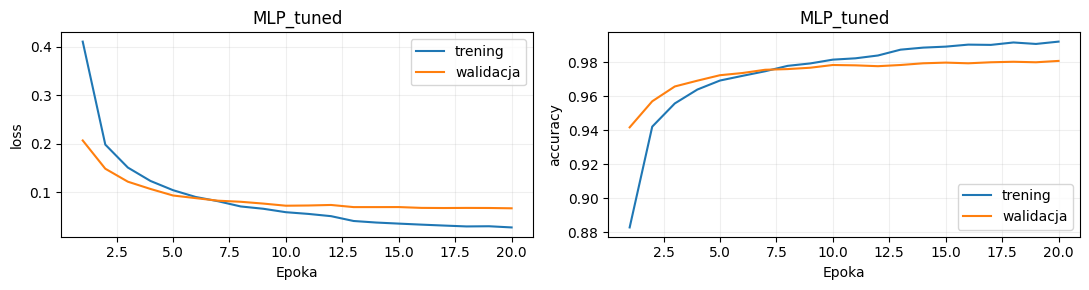

Najmniejsza strata walidacyjna wystąpiła w epoce **20**. Różnica train–validation accuracy w tej epoce: **1.13 p.p.** Rosnąca strata walidacyjna przy malejącej treningowej sugeruje przeuczenie. Przy Dropout i augmentacji metryki treningowe dotyczą trudniejszych warunków niż walidacyjne.

In [12]:
def mlp_objective(trial):
    params = dict(width=trial.suggest_categorical("width", [128, 256, 512]),
                  depth=trial.suggest_int("depth", 1, 3),
                  dropout=trial.suggest_categorical("dropout", [0.0, 0.2, 0.4]),
                  lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
                  batch_size=trial.suggest_categorical("batch_size", [64, 128]))
    model, h, row = train_model(build_mlp, params)
    trial.set_user_attr("val_accuracy", row["val_accuracy"])
    trial.set_user_attr("seconds", row["seconds"])
    return row["val_loss"]

study_mlp = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_mlp.optimize(mlp_objective, n_trials=CFG["trials_mlp"])
print("Najlepsze parametry MLP:", study_mlp.best_params)
mlp_tuned = run_named("MLP_tuned", build_mlp, study_mlp.best_params)
plot_history("MLP_tuned")

## 7. CNN — wykorzystujemy przestrzenną strukturę obrazu
Konwolucja 3×3 analizuje lokalne fragmenty, a ten sam filtr przesuwa po całym obrazie. Współdzielenie wag pomaga rozpoznawać podobne fragmenty w różnych miejscach. MaxPooling zmniejsza rozdzielczość map cech. Końcowa warstwa softmax podaje rozkład prawdopodobieństw dla cyfr 0–9.

Bazowa CNN ma dwa bloki: Conv(32) → ReLU → Pool oraz Conv(64) → ReLU → Pool, potem Dense(128). Do kontrolowanego porównania startujemy bez Dropout, BatchNorm i augmentacji. `padding="same"` zachowuje rozmiar podczas splotu; dwa poolingi zmieniają 28×28 → 14×14 → 7×7.

CNN_base {'val_loss': 0.0419, 'val_accuracy': 0.9891, 'seconds': 35.7654, 'parameters': 421642, 'epochs': 10, 'best_epoch': 5}


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_0_0 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1_0 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,264,928 (4.83 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 843,286 (3.22 MB)

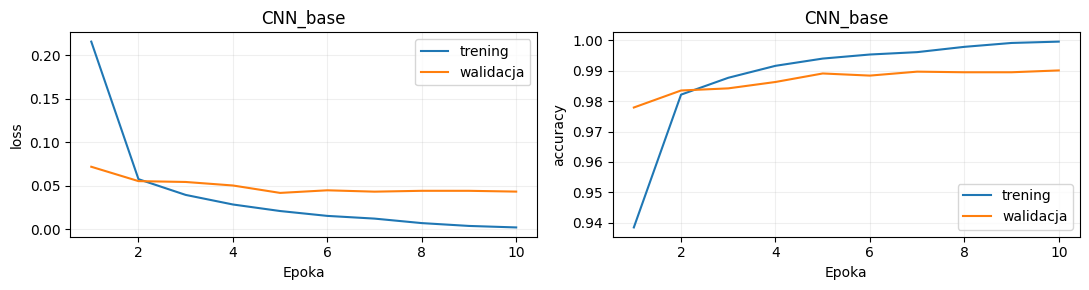

Najmniejsza strata walidacyjna wystąpiła w epoce **5**. Różnica train–validation accuracy w tej epoce: **0.49 p.p.** Rosnąca strata walidacyjna przy malejącej treningowej sugeruje przeuczenie. Przy Dropout i augmentacji metryki treningowe dotyczą trudniejszych warunków niż walidacyjne.

,val_accuracy,val_loss,parameters,seconds
name,,,,
MLP_base,0.9791,0.085840,101770,58.322787
MLP_tuned,0.9807,0.067336,203530,85.740587
CNN_base,0.9891,0.041876,421642,35.765411


In [13]:
def build_cnn(convs_per_block=1, filters=32, initializer="glorot_uniform",
              dropout=0.0, batchnorm=False, augment=False, lr=1e-3, batch_size=128):
    inputs = keras.Input((28, 28, 1))
    x = inputs
    if augment:
        # Niewielkie transformacje; odbicia mogłyby zmienić znaczenie cyfr.
        x = layers.RandomRotation(0.04, fill_mode="constant", fill_value=0.0)(x)
        x = layers.RandomTranslation(0.08, 0.08, fill_mode="constant", fill_value=0.0)(x)
    for block, channels in enumerate([filters, filters*2]):
        for conv in range(convs_per_block):
            # Nazwa inicjalizatora tworzy nowy obiekt dla każdej warstwy.
            x = layers.Conv2D(channels, 3, padding="same", use_bias=not batchnorm,
                              kernel_initializer=initializer, name=f"conv_{block}_{conv}")(x)
            if batchnorm:
                x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        if dropout:
            x = layers.SpatialDropout2D(dropout/2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", kernel_initializer=initializer)(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return compile_model(keras.Model(inputs, outputs, name="CNN"), lr)

cnn_base = run_named("CNN_base", build_cnn, {})
cnn_base.summary()
plot_history("CNN_base")
display(pd.DataFrame(records).set_index("name")[["val_accuracy", "val_loss", "parameters", "seconds"]])

### Jak interpretować porównanie MLP i CNN?
Wyższa accuracy oznacza większy odsetek poprawnych etykiet. Mniejsza cross-entropy oznacza lepsze przypisanie prawdopodobieństwa prawidłowej klasie; dwa modele z podobną accuracy mogą się tu różnić. Liczba parametrów nie jest równoznaczna z czasem obliczeń — filtry CNN stosujemy w wielu pozycjach. Ten eksperyment porównuje konkretne konfiguracje, nie dowodzi przewagi każdej CNN nad każdym MLP.

## 8A. Czy głębokość i HeUniform pomagają? Eksperyment 2×2
Porównujemy **2 i 4 warstwy konwolucyjne**, zachowując dwa poolingi i te same szerokości. Każdą głębokość badamy z GlorotUniform i HeUniform. Zmieniamy inicjalizację ukrytych warstw Conv/Dense, pozostawiając wspólną inicjalizację wyjścia softmax. W pozostałych ustawieniach nic nie zmieniamy.

HeUniform losuje wagi z przedziału $[-\sqrt{6/fan\_in},\sqrt{6/fan\_in}]$. Jest dostosowana do aktywacji ReLU i pomaga kontrolować skalę sygnału. **Nie gwarantuje wyższej dokładności.** Większa głębokość zwiększa zdolność reprezentacji, ale też koszt i ryzyko przeuczenia. Trzy ziarna w profilu pełnym pozwalają ocenić wrażliwość na losowość; nie stanowią jeszcze mocnego testu statystycznego.

Porównanie jest sparowane po ziarnach. Różne architektury zużywają losowość inaczej, więc to nie są identyczne wagi początkowe. Zwiększenie głębokości zmienia też liczbę parametrów — nie izolujemy głębokości od pojemności modelu.

CNN_d1_he_uniform_s42 {'val_loss': 0.0388, 'val_accuracy': 0.9893, 'seconds': 33.2717, 'parameters': 421642, 'epochs': 10, 'best_epoch': 5}
CNN_d2_glorot_uniform_s42 {'val_loss': 0.0377, 'val_accuracy': 0.9895, 'seconds': 40.9531, 'parameters': 467818, 'epochs': 8, 'best_epoch': 3}
CNN_d2_he_uniform_s42 {'val_loss': 0.0359, 'val_accuracy': 0.9909, 'seconds': 50.6189, 'parameters': 467818, 'epochs': 10, 'best_epoch': 5}
CNN_d1_glorot_uniform_s123 {'val_loss': 0.0434, 'val_accuracy': 0.9872, 'seconds': 35.4718, 'parameters': 421642, 'epochs': 11, 'best_epoch': 6}
CNN_d1_he_uniform_s123 {'val_loss': 0.0444, 'val_accuracy': 0.9897, 'seconds': 54.524, 'parameters': 421642, 'epochs': 15, 'best_epoch': 10}
CNN_d2_glorot_uniform_s123 {'val_loss': 0.0431, 'val_accuracy': 0.9893, 'seconds': 59.6542, 'parameters': 467818, 'epochs': 12, 'best_epoch': 7}
CNN_d2_he_uniform_s123 {'val_loss': 0.0406, 'val_accuracy': 0.99, 'seconds': 59.5931, 'parameters': 467818, 'epochs': 12, 'best_epoch': 7}
CNN_d1_

accuracy_mean  accuracy_std  loss_mean  time_mean  \
conv_layers initializer                                                         
2           glorot_uniform       0.988533      0.001159   0.044159  41.532945   
            he_uniform           0.989267      0.000451   0.043113  42.463460   
4           glorot_uniform       0.989400      0.000100   0.041394  51.667189   
            he_uniform           0.990633      0.000551   0.039927  56.549540   

                            parameters  
conv_layers initializer                 
2           glorot_uniform      421642  
            he_uniform          421642  
4           glorot_uniform      467818  
            he_uniform          467818

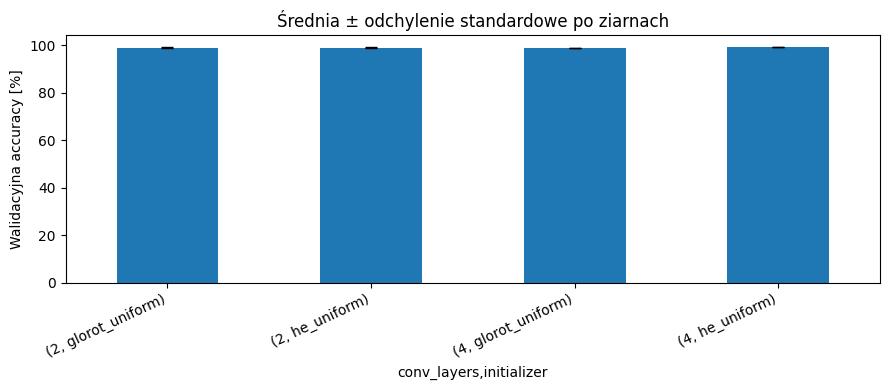

**Zmiana accuracy po HeUniform:** średnio +0.098 p.p. (zakres sparowanych różnic -0.050 do +0.250). **Zmiana po zwiększeniu głębokości:** +0.112 p.p. Znak dodatni oznacza poprawę. Sprawdź osobne wiersze tabeli: wpływ inicjalizacji może zależeć od głębokości. Małych różnic nie traktujemy jako pewnej przewagi.

In [14]:
ablation_rows = []
for seed in CFG["seeds"]:
    for depth in [1, 2]:
        for init in ["glorot_uniform", "he_uniform"]:
            name = f"CNN_d{depth}_{init}_s{seed}"
            # Identyczny wariant bazowy już wytrenowaliśmy — wykorzystujemy pomiar.
            if depth == 1 and init == "glorot_uniform" and seed == SEED:
                row = next(r for r in records if r["name"] == "CNN_base").copy()
            else:
                run_named(name, build_cnn, dict(convs_per_block=depth, initializer=init), seed)
                row = records[-1].copy()
            ablation_rows.append(dict(**row, conv_layers=2*depth, initializer=init))
ablation = pd.DataFrame(ablation_rows)
summary = ablation.groupby(["conv_layers", "initializer"]).agg(
    accuracy_mean=("val_accuracy", "mean"), accuracy_std=("val_accuracy", "std"),
    loss_mean=("val_loss", "mean"), time_mean=("seconds", "mean"), parameters=("parameters", "first"))
display(summary)
ax = (summary["accuracy_mean"]*100).plot.bar(yerr=summary["accuracy_std"].fillna(0)*100,
    capsize=4, figsize=(9, 4), ylabel="Walidacyjna accuracy [%]", title="Średnia ± odchylenie standardowe po ziarnach")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
paired = ablation.pivot(index=["seed", "conv_layers"], columns="initializer", values="val_accuracy")
he_delta = (paired["he_uniform"] - paired["glorot_uniform"])*100
by_depth = ablation.pivot(index=["seed", "initializer"], columns="conv_layers", values="val_accuracy")
depth_delta = (by_depth[4] - by_depth[2])*100
display(Markdown(f"**Zmiana accuracy po HeUniform:** średnio {he_delta.mean():+.3f} p.p. "
                 f"(zakres sparowanych różnic {he_delta.min():+.3f} do {he_delta.max():+.3f}). "
                 f"**Zmiana po zwiększeniu głębokości:** {depth_delta.mean():+.3f} p.p. "
                 "Znak dodatni oznacza poprawę. Sprawdź osobne wiersze tabeli: wpływ inicjalizacji "
                 "może zależeć od głębokości. Małych różnic nie traktujemy jako pewnej przewagi."))

## 8B. Optuna: wspólne strojenie CNN
Teraz szukamy dobrej konfiguracji praktycznej. Optuna dobiera głębokość, liczbę filtrów, inicjalizację, Dropout, BatchNorm, augmentację, learning rate i batch size. BatchNorm stabilizuje aktywacje, Dropout ogranicza poleganie na pojedynczych cechach, a augmentacja pokazuje zmienione przykłady wyłącznie podczas treningu. Zbyt mocna regularyzacja może pogorszyć wynik.

Włączamy do prób bazową CNN i głębszą wersję HeUniform. TPE przy małej liczbie prób nie przeszuka całej przestrzeni; wynik oznacza najlepszą **sprawdzoną** konfigurację. Pełny profil przeznacza CNN więcej prób niż MLP, zgodnie z naciskiem zadania — nie jest to porównanie przy równym koszcie strojenia. Kandydatów oceniamy początkowo przy jednym ziarnie, a zwycięzcę sprawdzamy ponownie przy trzech.

Najlepsze parametry CNN: {'convs_per_block': 2, 'filters': 32, 'initializer': 'he_uniform', 'dropout': 0.25, 'batchnorm': True, 'augment': True, 'lr': 0.001, 'batch_size': 128}
CNN_tuned_s42 {'val_loss': 0.0183, 'val_accuracy': 0.9946, 'seconds': 178.7544, 'parameters': 468394, 'epochs': 20, 'best_epoch': 20}
CNN_tuned_s123 {'val_loss': 0.0187, 'val_accuracy': 0.9941, 'seconds': 181.4765, 'parameters': 468394, 'epochs': 20, 'best_epoch': 20}
CNN_tuned_s2026 {'val_loss': 0.0181, 'val_accuracy': 0.994, 'seconds': 178.7911, 'parameters': 468394, 'epochs': 20, 'best_epoch': 18}


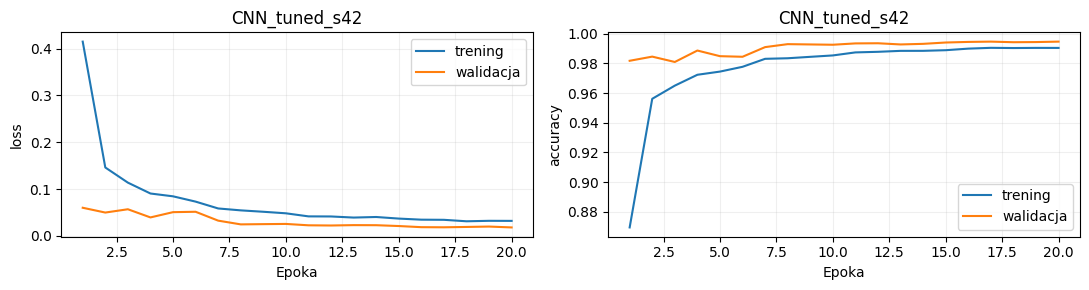

Najmniejsza strata walidacyjna wystąpiła w epoce **20**. Różnica train–validation accuracy w tej epoce: **-0.42 p.p.** Rosnąca strata walidacyjna przy malejącej treningowej sugeruje przeuczenie. Przy Dropout i augmentacji metryki treningowe dotyczą trudniejszych warunków niż walidacyjne.

,number,value,datetime_start,datetime_complete,duration,params_augment,params_batch_size,params_batchnorm,params_convs_per_block,params_dropout,params_filters,params_initializer,params_lr,user_attrs_seconds,user_attrs_val_accuracy,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
1,1,0.018256,2026-10-21 17:19:33.245550,2026-10-21 17:22:36.220478,0 days 00:03:02.974928,True,128,True,2,0.25,32,he_uniform,0.001000,180.936608,0.9946,"{'convs_per_block': 2, 'filters': 32, 'initial...",NaN,COMPLETE
15,15,0.018411,2026-10-21 17:56:10.318054,2026-10-21 18:00:24.765747,0 days 00:04:14.447693,True,128,True,2,0.25,48,he_uniform,0.000681,250.967961,0.9949,NaN,"{""augment"": true, ""batch_size"": 128, ""batchnor...",COMPLETE
16,16,0.019049,2026-10-21 18:00:24.765906,2026-10-21 18:03:26.527429,0 days 00:03:01.761523,True,128,True,2,0.25,32,he_uniform,0.000500,179.529476,0.9935,NaN,"{""augment"": true, ""batch_size"": 128, ""batchnor...",COMPLETE
10,10,0.019338,2026-10-21 17:40:43.716021,2026-10-21 17:45:03.717139,0 days 00:04:20.001118,True,128,True,2,0.25,48,he_uniform,0.002072,257.738190,0.9937,NaN,"{""augment"": true, ""batch_size"": 128, ""batchnor...",COMPLETE
11,11,0.019766,2026-10-21 17:45:03.717270,2026-10-21 17:49:23.882299,0 days 00:04:20.165029,True,128,True,2,0.25,48,he_uniform,0.002198,257.863488,0.9947,NaN,"{""augment"": true, ""batch_size"": 128, ""batchnor...",COMPLETE
12,12,0.020608,2026-10-21 17:49:23.882398,2026-10-21 17:52:26.462087,0 days 00:03:02.579689,True,128,True,2,0.40,32,he_uniform,0.000924,180.346911,0.9934,NaN,"{""augment"": true, ""batch_size"": 128, ""batchnor...",COMPLETE
19,19,0.020749,2026-10-21 18:08:02.444095,2026-10-21 18:10:20.169664,0 days 00:02:17.725569,True,128,True,2,0.25,16,glorot_uniform,0.000820,135.504851,0.9933,NaN,"{""augment"": true, ""batch_size"": 128, ""batchnor...",COMPLETE
9,9,0.020999,2026-10-21 17:38:23.676501,2026-10-21 17:40:43.715891,0 days 00:02:20.039390,True,128,False,2,0.00,48,glorot_uniform,0.000427,137.914124,0.9942,NaN,NaN,COMPLETE
5,5,0.022590,2026-10-21 17:27:01.695459,2026-10-21 17:30:09.312031,0 days 00:03:07.616572,True,64,False,2,0.25,32,glorot_uniform,0.000252,185.666331,0.9937,NaN,NaN,COMPLETE
7,7,0.025053,2026-10-21 17:32:31.713663,2026-10-21 17:35:09.702717,0 days 00:02:37.989054,True,64,False,2,0.40,16,he_uniform,0.000675,155.890350,0.9930,NaN,NaN,COMPLETE


,seed,val_accuracy,val_loss,seconds
14,42,0.9946,0.018256,178.754445
15,123,0.9941,0.018716,181.476505
16,2026,0.9940,0.018053,178.791145


Średnia accuracy powtórzeń: 0.9942333300908407 | SD: 0.0003214527416876689


In [15]:
def cnn_objective(trial):
    params = dict(convs_per_block=trial.suggest_int("convs_per_block", 1, 2),
                  filters=trial.suggest_categorical("filters", [16, 32, 48]),
                  initializer=trial.suggest_categorical("initializer", ["glorot_uniform", "he_uniform"]),
                  dropout=trial.suggest_categorical("dropout", [0.0, 0.25, 0.4]),
                  batchnorm=trial.suggest_categorical("batchnorm", [False, True]),
                  augment=trial.suggest_categorical("augment", [False, True]),
                  lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
                  batch_size=trial.suggest_categorical("batch_size", [64, 128]))
    model, h, row = train_model(build_cnn, params)
    trial.set_user_attr("val_accuracy", row["val_accuracy"])
    trial.set_user_attr("seconds", row["seconds"])
    return row["val_loss"]

study_cnn = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_cnn.enqueue_trial(dict(convs_per_block=1, filters=32, initializer="glorot_uniform",
                            dropout=0.0, batchnorm=False, augment=False, lr=1e-3, batch_size=128))
study_cnn.enqueue_trial(dict(convs_per_block=2, filters=32, initializer="he_uniform",
                            dropout=0.25, batchnorm=True, augment=True, lr=1e-3, batch_size=128))
study_cnn.optimize(cnn_objective, n_trials=CFG["trials_cnn"])
print("Najlepsze parametry CNN:", study_cnn.best_params)
for seed in CFG["seeds"]:
    run_named(f"CNN_tuned_s{seed}", build_cnn, study_cnn.best_params, seed)
plot_history(f"CNN_tuned_s{SEED}")
display(study_cnn.trials_dataframe().sort_values("value").head(10))
cnn_repeats = pd.DataFrame(records).query("name.str.startswith('CNN_tuned')", engine="python")
display(cnn_repeats[["seed", "val_accuracy", "val_loss", "seconds"]])
print("Średnia accuracy powtórzeń:", cnn_repeats.val_accuracy.mean(),
      "| SD:", cnn_repeats.val_accuracy.std())
# Powtórzenia walidacyjne oceniają stabilność, nie wybieramy szczęśliwego ziarna do testu.

## 5 i 7–8. Końcowa ocena na 10 000 obrazów testowych
Zamrażamy konfiguracje i używamy z góry ustalonego ziarna 42. Testujemy cztery modele: bazowy i strojony MLP oraz bazową i strojoną CNN. Nie wybieramy modelu na podstawie wyników testowych. Model do dalszej analizy wskazuje najmniejsza strata walidacyjna wśród tych czterech kandydatów.

Przedział Wilsona dla accuracy pokazuje niepewność wynikającą ze skończonej próbki testowej (przy założeniu niezależnych przykładów). Nie uwzględnia losowości treningu ani przesunięcia rozkładu. Nakładanie się przedziałów nie jest testem istotności różnicy modeli.

Model wybrany na walidacji przed testem: CNN_tuned_s42


,test_accuracy,test_loss,macro_f1,errors,ci95_low,ci95_high,val_accuracy,parameters,seconds,best_epoch
name,,,,,,,,,,
MLP_base,0.9775,0.07845,0.97737,225,0.97440,0.98023,0.9791,101770,58.32279,17
MLP_tuned,0.9821,0.06102,0.98201,179,0.97931,0.98452,0.9807,203530,85.74059,20
CNN_base,0.9912,0.02739,0.99119,88,0.98917,0.99285,0.9891,421642,35.76541,5
CNN_tuned_s42,0.9956,0.01307,0.99560,44,0.99410,0.99672,0.9946,468394,178.75444,20


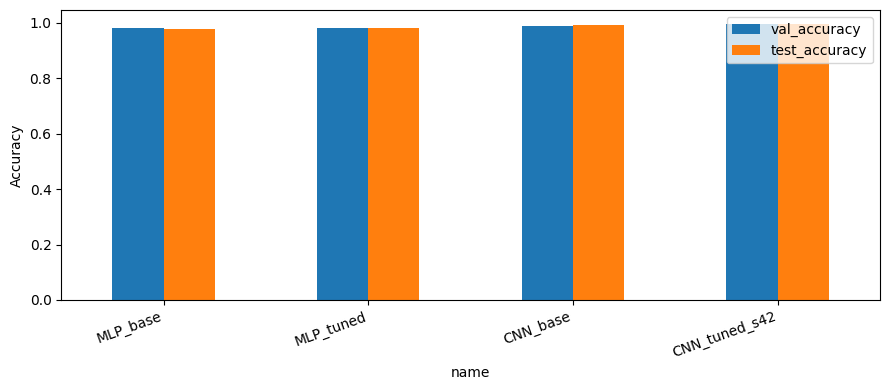

Strojona CNN zmieniła testową accuracy względem bazowej o **+0.440 p.p.** To odpowiada około **44** klasyfikacjom w tym teście. Wartość ujemna oznacza pogorszenie: strojenie walidacyjne nie gwarantuje poprawy na teście. Porównaj również stratę, liczbę błędów i koszt treningu. Czas w tabeli dotyczy jednego treningu, a nie całego kosztu poszukiwania.

In [16]:
from sklearn.metrics import f1_score
final_names = ["MLP_base", "MLP_tuned", "CNN_base", f"CNN_tuned_s{SEED}"]
validation_table = pd.DataFrame(records).set_index("name")
selected_name = validation_table.loc[final_names, "val_loss"].idxmin()
print("Model wybrany na walidacji przed testem:", selected_name)

def wilson(correct, n, z=1.96):
    p = correct/n
    center = (p + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half

test_rows, predictions = [], {}
for name in final_names:
    model = keras.models.load_model(model_paths[name])
    scores = model.evaluate(x_test, y_test, verbose=0, return_dict=True)
    prob = model.predict(x_test, batch_size=256, verbose=0)
    pred = prob.argmax(axis=1)
    predictions[name] = prob
    lo, hi = wilson(int((pred == y_test_int).sum()), len(pred))
    test_rows.append(dict(name=name, test_accuracy=scores["accuracy"], test_loss=scores["loss"],
                          macro_f1=f1_score(y_test_int, pred, average="macro"),
                          errors=int((pred != y_test_int).sum()), ci95_low=lo, ci95_high=hi))
results = pd.DataFrame(test_rows).set_index("name").join(
    validation_table[["val_accuracy", "parameters", "seconds", "best_epoch"]])
display(results.round(5))
results[["val_accuracy", "test_accuracy"]].plot.bar(figsize=(9, 4), ylabel="Accuracy")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
delta = 100*(results.loc[f"CNN_tuned_s{SEED}", "test_accuracy"] - results.loc["CNN_base", "test_accuracy"])
display(Markdown(f"Strojona CNN zmieniła testową accuracy względem bazowej o **{delta:+.3f} p.p.** "
                 f"To odpowiada około **{abs(delta)*len(y_test_int)/100:.0f}** klasyfikacjom w tym teście. "
                 "Wartość ujemna oznacza pogorszenie: strojenie walidacyjne nie gwarantuje poprawy na teście. "
                 "Porównaj również stratę, liczbę błędów i koszt treningu. Czas w tabeli dotyczy jednego "
                 "treningu, a nie całego kosztu poszukiwania."))

### Predykcje i analiza pomyłek
Pokazujemy te same przykłady dla strojonego MLP i CNN oraz macierz pomyłek modelu wybranego na walidacji. Wiersz macierzy to prawdziwa cyfra, kolumna — przewidziana. Wynik softmax to pewność modelu, nie gwarancja poprawności i nie dowód kalibracji.

Pomyłki analizujemy po zamknięciu eksperymentu. Ewentualne kolejne pomysły należy sprawdzać na walidacji; wielokrotne dopasowywanie rozwiązania do tego testu osłabia jego rolę niezależnej oceny.

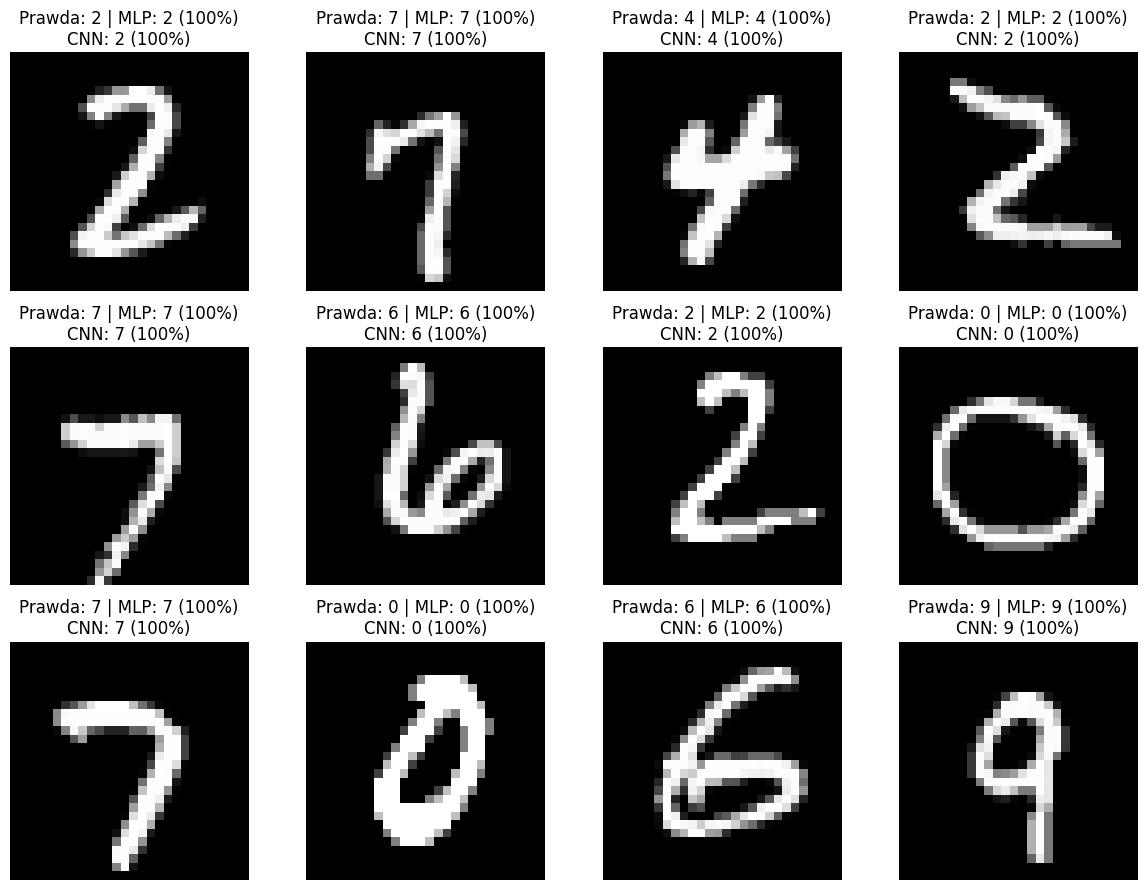

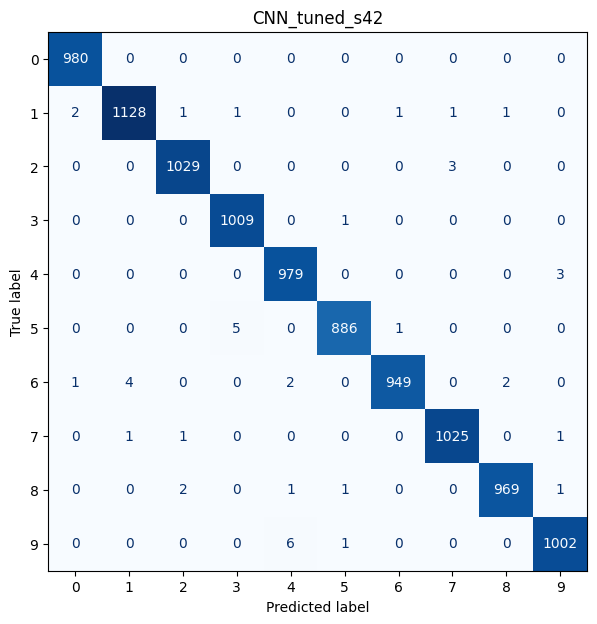

              precision    recall  f1-score   support

           0     0.9969    1.0000    0.9985       980
           1     0.9956    0.9938    0.9947      1135
           2     0.9961    0.9971    0.9966      1032
           3     0.9941    0.9990    0.9965      1010
           4     0.9909    0.9969    0.9939       982
           5     0.9966    0.9933    0.9949       892
           6     0.9979    0.9906    0.9942       958
           7     0.9961    0.9971    0.9966      1028
           8     0.9969    0.9949    0.9959       974
           9     0.9950    0.9931    0.9940      1009

    accuracy                         0.9956     10000
   macro avg     0.9956    0.9956    0.9956     10000
weighted avg     0.9956    0.9956    0.9956     10000

Najczęstsza kierunkowa pomyłka: 9 → 4, liczba: 6.


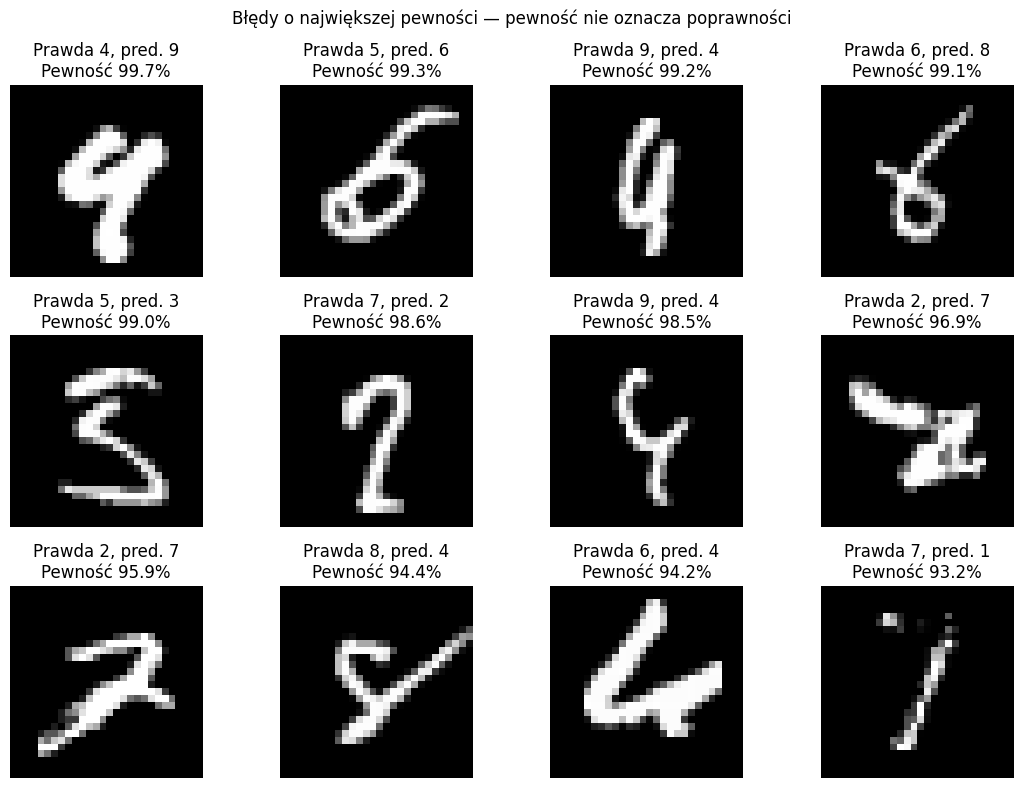

In [17]:
sample_ids = np.random.default_rng(SEED).choice(len(x_test), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, i in zip(axes.flat, sample_ids):
    m = predictions["MLP_tuned"][i]
    q = predictions[f"CNN_tuned_s{SEED}"][i]
    ax.imshow(x_test[i, ..., 0], cmap="gray")
    ax.set_title(f"Prawda: {y_test_int[i]} | MLP: {m.argmax()} ({m.max():.0%})\nCNN: {q.argmax()} ({q.max():.0%})")
    ax.axis("off")
plt.tight_layout(); plt.show()
probs = predictions[selected_name]
pred = probs.argmax(axis=1)
cm = confusion_matrix(y_test_int, pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(selected_name); plt.show()
print(classification_report(y_test_int, pred, digits=4, zero_division=0))
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
a, b = np.unravel_index(cm_off.argmax(), cm_off.shape)
if cm_off[a, b]:
    print(f"Najczęstsza kierunkowa pomyłka: {a} → {b}, liczba: {cm_off[a,b]}.")
wrong = np.flatnonzero(pred != y_test_int)
wrong = wrong[np.argsort(probs[wrong].max(axis=1))[::-1]][:12]
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(11, 8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(x_test[i, ..., 0], cmap="gray")
        ax.set_title(f"Prawda {y_test_int[i]}, pred. {pred[i]}\nPewność {probs[i].max():.1%}")
    plt.suptitle("Błędy o największej pewności — pewność nie oznacza poprawności")
    plt.tight_layout(); plt.show()
else:
    print("Brak błędów na tym zbiorze.")

### Co widzi CNN? Mapy cech
Wyświetlamy odpowiedzi pierwszej warstwy konwolucyjnej strojonej CNN na jeden obraz. To wyuczone lokalne przekształcenia, a nie gotowe obrazki cyfr. Część filtrów może reagować na kreski lub kontrast, część być mało aktywna. Nie przypisujemy każdemu filtrowi jednoznacznego znaczenia. Wywołanie z `training=False` wyłącza augmentację i Dropout oraz ustawia BatchNorm w tryb inferencji.

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


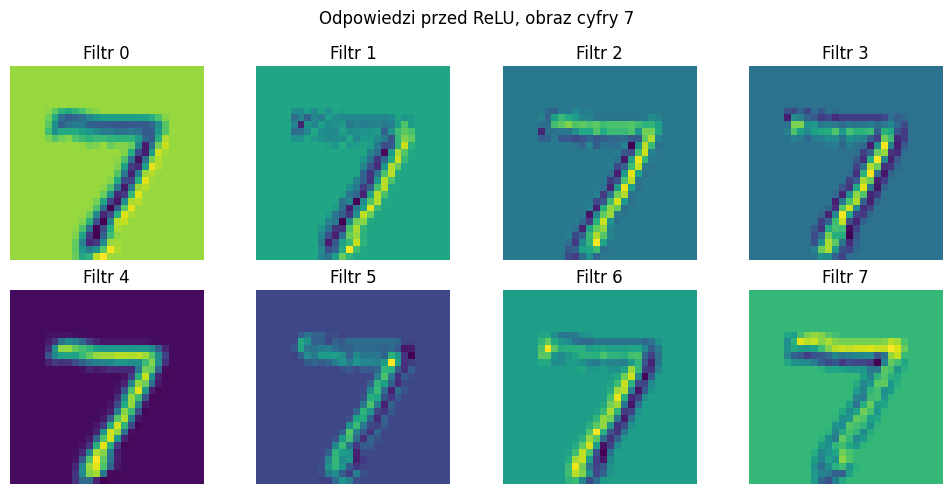

In [18]:
cnn_inspect = keras.models.load_model(model_paths[f"CNN_tuned_s{SEED}"])
first_conv = next(layer for layer in cnn_inspect.layers if isinstance(layer, layers.Conv2D))
extractor = keras.Model(cnn_inspect.inputs, first_conv.output)
feature_maps = extractor(x_test[:1], training=False).numpy()[0]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[..., k], cmap="viridis"); ax.set_title(f"Filtr {k}"); ax.axis("off")
plt.suptitle(f"Odpowiedzi przed ReLU, obraz cyfry {y_test_int[0]}")
plt.tight_layout(); plt.show()

## Podsumowanie eksperymentu i zapis wyników
Rozdzielamy dwie odpowiedzi: kontrolowane porównanie 2×2 ocenia konkretne zmiany, a Optuna szuka skutecznego zestawu ustawień. Poprawy całego zestawu nie można przypisać wyłącznie HeUniform lub większej głębokości.

Przy interpretacji sprawdź: (1) zmianę liczby błędów, (2) rozrzut między ziarnami, (3) lukę train–validation i przebieg straty, (4) koszt treningu. Wielokrotne próby mogą dopasować hiperparametry do walidacji. Mocniejsza ocena wymagałaby dodatkowych podziałów lub zagnieżdżonej walidacji, co zwiększa koszt. Wyniki MNIST nie mówią wprost, jak model zachowa się na zdjęciach cyfr z telefonu.

In [19]:
results.to_csv(OUT / "porownanie_testowe.csv")
ablation.to_csv(OUT / "eksperyment_glebokosc_inicjalizacja.csv", index=False)
summary.to_csv(OUT / "podsumowanie_ablacji.csv")
study_mlp.trials_dataframe().to_csv(OUT / "optuna_mlp.csv", index=False)
study_cnn.trials_dataframe().to_csv(OUT / "optuna_cnn.csv", index=False)
metadata = dict(profile=PROFILE, config=CFG, tensorflow=tf.__version__, optuna=optuna.__version__,
                numpy=np.__version__, python=platform.python_version(), seed=SEED,
                best_mlp=study_mlp.best_params, best_cnn=study_cnn.best_params,
                selected_on_validation=selected_name,
                search_seconds_mlp=sum(t.user_attrs["seconds"] for t in study_mlp.trials),
                search_seconds_cnn=sum(t.user_attrs["seconds"] for t in study_cnn.trials))
(OUT / "eksperyment.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
(OUT / "historie.json").write_text(json.dumps(histories, indent=2), encoding="utf-8")
print("Zapisano modele, tabele, parametry i historie w:", OUT.resolve())
if SMOKE:
    display(Markdown("**To był test techniczny. Wnioski jakościowe wymagają ponownego uruchomienia w profilu `full`.**"))

Zapisano modele, tabele, parametry i historie w: /content/wyniki_mnist/full


## Jak rozumiem MLP i CNN — własnymi słowami

**MLP** traktuję jak zespół osób, którym podaję długą listę 784 liczb opisujących jasność pikseli. Każda osoba tworzy własną ważoną kombinację tych liczb, a kolejne warstwy łączą uzyskane sygnały. Sieć może nauczyć się rozpoznawać cyfry, ale nie dostaje wprost informacji, że dwa piksele są sąsiadami. Spłaszczenie nie usuwa wartości ani ustalonego porządku pikseli — usuwa jawny dwuwymiarowy układ w operacjach warstwy Dense. Zależności przestrzenne MLP musi wywnioskować z przykładów.

**CNN** wyobrażam sobie jako przesuwanie po obrazie małych okienek. Każdy filtr sprawdza w wielu miejscach pewien lokalny wzór. Początkowo filtry są losowe; trening uczy je reagować na przydatne fragmenty. Kolejne warstwy mogą składać proste sygnały w bardziej złożone układy, a końcowy klasyfikator decyduje, do której cyfry pasuje całość. Wagi filtra są wspólne dla różnych miejsc obrazu, więc nie trzeba osobno uczyć tego samego detektora dla każdego położenia.

**Pooling** zmniejsza mapę cech i może ograniczać wrażliwość na drobne przesunięcia, ale traci część informacji. CNN nie jest automatycznie odporna na dowolne przesunięcia czy obroty. **Głębsza sieć** ma więcej etapów przetwarzania, jednak nie zawsze uczy się lepiej. **HeUniform** daje wagom skalę startową pasującą do ReLU; nie przekazuje modelowi wiedzy o cyfrach. **Dropout i augmentacja** utrudniają zapamiętanie treningu, ale w nadmiarze mogą przeszkadzać w nauce.

Najważniejsza różnica w moim rozumieniu: MLP uczy się ogólnych zależności między wejściowymi liczbami, a CNN wbudowuje w sposób przetwarzania założenie, że lokalne wzory i ich powtarzalność w przestrzeni są istotne. To dobre założenie dla obrazów, dlatego prosta CNN często jest bardzo mocnym punktem wyjścia.

## Źródła
- [Keras: MNIST, wczytywanie danych](https://keras.io/api/datasets/mnist/)
- [Keras: przykład prostej CNN dla MNIST](https://keras.io/examples/vision/mnist_convnet/)
- [Keras: inicjalizatory, w tym HeUniform](https://keras.io/api/layers/initializers/)
- [Keras: odtwarzalność eksperymentów](https://keras.io/examples/keras_recipes/reproducibility_recipes/)
- [Optuna: pierwsze kroki](https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/001_first.html)
- [Opis MNIST wskazany w zadaniu](https://aivision.pl/mnist/)